In [13]:
import numpy as np
import modules.SimulacaoKTz as sim
import modules.ajuste_intervalodinamico as dynran

K          = 0.2
Tc         = 1.0 - K
delta      = 0.0
lamb       = 0.0
xR         = 0.0
H_valores  = np.logspace(-6,0,100)

t_transiente = 10000
t_total      = 20000
x0           = np.array((0.5,0.6),dtype=float)

T1 = Tc-0.3
T2 = Tc
T3 = Tc+0.3


x_m1,x_max1,x_var1,x_var_std1,x_suscept1 = sim.RodaSimulacao_Varios_H(K,T1,delta,lamb,xR,H_valores,t_transiente,t_total,x0,'kttanh',alpha_grad=1.0e-6,suscept_max_grad=1.0e2,seguir_ponto_fixo=False,usar_modulo_de_m=False,percent_amostras_bootstrap=0.5,num_repete_bootstrap=0)
x_m2,x_max2,x_var2,x_var_std2,x_suscept2 = sim.RodaSimulacao_Varios_H(K,T2,delta,lamb,xR,H_valores,t_transiente,t_total,x0,'kttanh',alpha_grad=1.0e-6,suscept_max_grad=1.0e2,seguir_ponto_fixo=False,usar_modulo_de_m=False,percent_amostras_bootstrap=0.5,num_repete_bootstrap=0)
x_m3,x_max3,x_var3,x_var_std3,x_suscept3 = sim.RodaSimulacao_Varios_H(K,T3,delta,lamb,xR,H_valores,t_transiente,t_total,x0,'kttanh',alpha_grad=1.0e-6,suscept_max_grad=1.0e2,seguir_ponto_fixo=False,usar_modulo_de_m=False,percent_amostras_bootstrap=0.5,num_repete_bootstrap=0)

chi1 = sim.KT_susceptibilidade(K,T1,H_valores,x_m1)
chi2 = sim.KT_susceptibilidade(K,T1,H_valores,x_m2)
chi3 = sim.KT_susceptibilidade(K,T1,H_valores,x_m3)

chib1 = sim.KT_susceptibilidade2(K,T1,H_valores,x_m1)
chib2 = sim.KT_susceptibilidade2(K,T1,H_valores,x_m2)
chib3 = sim.KT_susceptibilidade2(K,T1,H_valores,x_m3)

H_delta1, m_selecionado1, H_selecionado1 = dynran.intervalo_dinamico(x_m1,H_valores)
H_delta2, m_selecionado2, H_selecionado2 = dynran.intervalo_dinamico(x_m2,H_valores)
H_delta3, m_selecionado3, H_selecionado3 = dynran.intervalo_dinamico(x_m3,H_valores)

dmdH1 = np.diff(x_m1)/np.diff(H_valores)
dmdH2 = np.diff(x_m2)/np.diff(H_valores)
dmdH3 = np.diff(x_m3)/np.diff(H_valores)

m_grad1 = np.gradient(x_m1,H_valores)
m_grad2 = np.gradient(x_m2,H_valores)
m_grad3 = np.gradient(x_m3,H_valores)

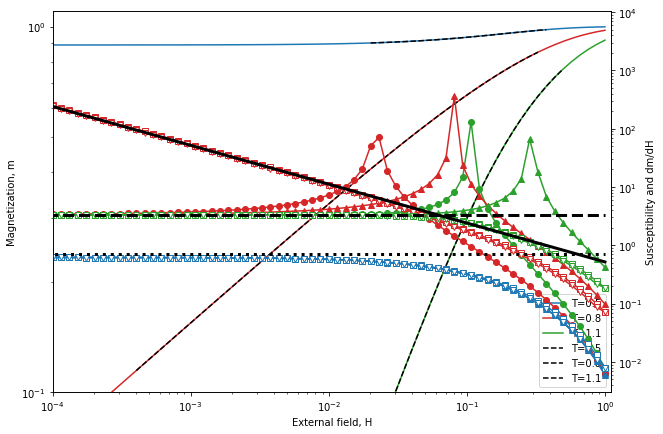

In [22]:
import matplotlib.pyplot as plt


dmdH_theory_Tc    = lambda K,T,H: ((1/3)*(3/T)**(1/3))*H**(-2/3)
dmdH_theory_sub   = lambda K,T,H: np.ones_like(H)/(T - (1-K))
dmdH_theory_super = lambda K,T,H: np.ones_like(H)/( (T/(1-np.sqrt(3*(1-K-T)/T)**2)) -(1-K)  )


fig,ax = plt.subplots(nrows=1,ncols=1,figsize=(10,7))

ax.plot(H_valores,x_m1,label=f'T={T1:g}',c='tab:blue')
ax.plot(H_valores,x_m2,label=f'T={T2:g}',c='tab:red')
ax.plot(H_valores,x_m3,label=f'T={T3:g}',c='tab:green')
ax.plot(H_selecionado1,m_selecionado1,ls='--',c='k',label=f'T={T1:g}')
ax.plot(H_selecionado2,m_selecionado2,ls='--',c='k',label=f'T={T2:g}')
ax.plot(H_selecionado3,m_selecionado3,ls='--',c='k',label=f'T={T3:g}')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim((1e-4,1.1))
ax.set_ylim((1e-1,1.1))

ax.legend()

ax2 = ax.twinx()

ax2.plot(H_valores,np.abs(chi1),marker='o',label=f'T={T1:g}',c='tab:blue')
ax2.plot(H_valores,np.abs(chi2),marker='o',label=f'T={T2:g}',c='tab:red')
ax2.plot(H_valores,np.abs(chi3),marker='o',label=f'T={T3:g}',c='tab:green')
ax2.plot(H_valores,np.abs(chib1),marker='^',label=f'T={T1:g}',c='tab:blue')
ax2.plot(H_valores,np.abs(chib2),marker='^',label=f'T={T2:g}',c='tab:red')
ax2.plot(H_valores,np.abs(chib3),marker='^',label=f'T={T3:g}',c='tab:green')
ax2.plot(H_valores[1:],dmdH1,marker='s',markerfacecolor='w',label=f'T={T1:g}',c='tab:blue')
ax2.plot(H_valores[1:],dmdH2,marker='s',markerfacecolor='w',label=f'T={T2:g}',c='tab:red')
ax2.plot(H_valores[1:],dmdH3,marker='s',markerfacecolor='w',label=f'T={T3:g}',c='tab:green')
ax2.plot(H_valores,m_grad1,marker='v',markerfacecolor='w',label=f'T={T1:g}',c='tab:blue')
ax2.plot(H_valores,m_grad2,marker='v',markerfacecolor='w',label=f'T={T2:g}',c='tab:red')
ax2.plot(H_valores,m_grad3,marker='v',markerfacecolor='w',label=f'T={T3:g}',c='tab:green')

ax2.plot(H_valores,np.abs(dmdH_theory_super(K,T1,H_valores)),ls=':',lw=3,c='k',label=f'T={T1:g}')
ax2.plot(H_valores,dmdH_theory_Tc(K,T2,H_valores) ,ls='-' ,lw=3,c='k',label=f'T={T2:g}')
ax2.plot(H_valores,dmdH_theory_sub(K,T3,H_valores),ls='--',lw=3,c='k',label=f'T={T3:g}')




ax2.set_yscale('log')

ax.set_xlabel('External field, H')
ax.set_ylabel('Magnetization, m')
ax2.set_ylabel('Susceptibility and dm/dH')
plt.show()

In [74]:
import numpy as np
import modules.SimulacaoKTz as sim
import modules.ajuste_intervalodinamico as dynran

K          = 0.2
Tc         = 1.0 - K
delta      = 0.0
lamb       = 0.0
xR         = 0.0
H_valores  = np.logspace(-6,0,100)

t_transiente = 10000
t_total      = 20000
x0           = np.array((0.5,0.6),dtype=float)

T1 = Tc-0.3
T2 = Tc+0.3

#T_values = np.unique(np.append(np.linspace(T1,T2,30),Tc))
#T1_log10 = np.log10(Tc-1e-6)
T1_log10 = np.log10(Tc-1e-1)
T1a_log10 = np.log10(Tc-1e-4)
T2a_log10 = np.log10(Tc-1e-4)
T2_log10 = np.log10(Tc-1e-8)
T3_log10 = np.log10(Tc+1e-8)
T3a_log10 = np.log10(Tc+1e-4)
T4a_log10 = np.log10(Tc+1e-4)
T4_log10 = np.log10(Tc+1e-1)
#T4_log10 = np.log10(Tc+1e-6)
n_T      = 50
T_values = np.unique(np.concatenate((np.logspace(T1_log10,T1a_log10,n_T//2),
                                     np.logspace(T2a_log10,T2_log10,n_T//2),
                                     np.array([Tc]),
                                     np.logspace(T3_log10,T3a_log10,n_T//2),
                                     np.logspace(T4a_log10,T4_log10,n_T//2),
                                     )))

x_m_lst           = []
x_max_lst         = []
x_var_lst         = []
x_var_std_lst     = []
x_suscept_lst     = []
H_delta_lst       = []
m_selecionado_lst = []
H_selecionado_lst = []

for k,T in enumerate(T_values):
    x_m,x_max,x_var,x_var_std,x_suscept   = sim.RodaSimulacao_Varios_H(K,T,delta,lamb,xR,H_valores,t_transiente,t_total,x0,'kttanh',alpha_grad=1.0e-6,suscept_max_grad=1.0e2,seguir_ponto_fixo=False,usar_modulo_de_m=False,percent_amostras_bootstrap=0.5,num_repete_bootstrap=0)
    H_delta, m_selecionado, H_selecionado = dynran.intervalo_dinamico(x_m,H_valores)
    x_m_lst.append(x_m)
    x_max_lst.append(x_max)
    x_var_lst.append(x_var)
    x_var_std_lst.append(x_var_std)
    x_suscept_lst.append(x_suscept)
    H_delta_lst.append(H_delta)
    m_selecionado_lst.append(m_selecionado)
    H_selecionado_lst.append(H_selecionado)


In [75]:
T_values

array([0.7       , 0.70390185, 0.70782546, 0.71177093, 0.7157384 ,
       0.71972798, 0.7237398 , 0.72777398, 0.73183065, 0.73590993,
       0.74001195, 0.74413683, 0.74828471, 0.7524557 , 0.75664995,
       0.76086757, 0.76510871, 0.76937348, 0.77366203, 0.77797448,
       0.78231097, 0.78667163, 0.7910566 , 0.79546601, 0.7999    ,
       0.79990417, 0.79990833, 0.7999125 , 0.79991666, 0.79992083,
       0.799925  , 0.79992916, 0.79993333, 0.79993749, 0.79994166,
       0.79994583, 0.79994999, 0.79995416, 0.79995833, 0.79996249,
       0.79996666, 0.79997082, 0.79997499, 0.79997916, 0.79998332,
       0.79998749, 0.79999166, 0.79999582, 0.79999999, 0.8       ,
       0.80000001, 0.80000418, 0.80000834, 0.80001251, 0.80001667,
       0.80002084, 0.80002501, 0.80002917, 0.80003334, 0.8000375 ,
       0.80004167, 0.80004584, 0.80005   , 0.80005417, 0.80005834,
       0.8000625 , 0.80006667, 0.80007083, 0.800075  , 0.80007917,
       0.80008333, 0.8000875 , 0.80009167, 0.80009583, 0.8001 

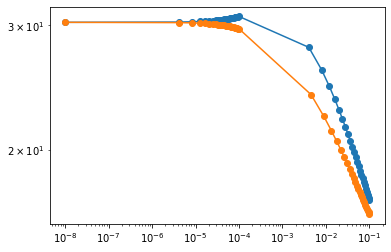

In [79]:
dH    = np.array(H_delta_lst)

ind_c     = np.nonzero(T_values == Tc)[0][0]
ind_super = np.arange(ind_c+1,T_values.size)
ind_sub   = np.arange(0,ind_c)

fig,ax = plt.subplots(nrows=1,ncols=1)

#ax.plot(T_values,dH,'-o',label=f'K={K:g}')
ax.plot(np.abs(T_values[ind_super]- Tc),dH[ind_super],'-o',label=f'K={K:g}')
ax.plot(np.abs(T_values[ind_sub]  - Tc),dH[ind_sub]  ,'-o',label=f'K={K:g}')

ax.set_yscale('log')
ax.set_xscale('log')

plt.show()

In [73]:
print(np.abs(T_values[ind_super]- Tc))
print(np.abs(T_values[ind_sub]  - Tc))

[1.00000001e-08 1.92531119e-03 3.85524586e-03 5.78982516e-03
 7.72906026e-03 9.67296239e-03 1.16215428e-02 1.35748126e-02
 1.55327833e-02 1.74954661e-02 1.94628723e-02 2.14350133e-02
 2.34119005e-02 2.53935454e-02 2.73799593e-02 2.93711538e-02
 3.13671404e-02 3.33679306e-02 3.53735359e-02 3.73839679e-02
 3.93992383e-02 4.14193587e-02 4.34443408e-02 4.54741963e-02
 4.75089369e-02 4.95485743e-02 5.15931204e-02 5.36425869e-02
 5.56969857e-02 5.77563287e-02 5.98206278e-02 6.18898949e-02
 6.39641419e-02 6.60433808e-02 6.81276238e-02 7.02168827e-02
 7.23111696e-02 7.44104968e-02 7.65148762e-02 7.86243201e-02
 8.07388406e-02 8.28584500e-02 8.49831605e-02 8.71129844e-02
 8.92479340e-02 9.13880216e-02 9.35332596e-02 9.56836604e-02
 9.78392363e-02 1.00000000e-01]
[1.00000000e-01 9.80898073e-02 9.61744019e-02 9.42537697e-02
 9.23278964e-02 9.03967677e-02 8.84603692e-02 8.65186866e-02
 8.45717055e-02 8.26194113e-02 8.06617896e-02 7.86988259e-02
 7.67305055e-02 7.47568139e-02 7.27777364e-02 7.07932